In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import ElasticNet, Ridge, SGDRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
import time

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
base_path = '/kaggle/input/Cinema_Audience_Forecasting_challenge'

movie_theater_relation = pd.read_csv(f'{base_path}/movie_theater_id_relation/movie_theater_id_relation.csv')
date_info = pd.read_csv(f'{base_path}/date_info/date_info.csv')
booknow_theaters = pd.read_csv(f'{base_path}/booknow_theaters/booknow_theaters.csv')
cinePOS_booking = pd.read_csv(f'{base_path}/cinePOS_booking/cinePOS_booking.csv')
cinePOS_theaters = pd.read_csv(f'{base_path}/cinePOS_theaters/cinePOS_theaters.csv')
booknow_visits = pd.read_csv(f'{base_path}/booknow_visits/booknow_visits.csv')
booknow_booking = pd.read_csv(f'{base_path}/booknow_booking/booknow_booking.csv')
sample_submission = pd.read_csv(f'{base_path}/sample_submission/sample_submission.csv')

print(f"Training data: {booknow_visits.shape}")
print(f"Test data: {sample_submission.shape}")
print("All datasets loaded successfully")

Training data: (214046, 3)
Test data: (38062, 2)
All datasets loaded successfully



Target Variable Statistics:
count    214046.000000
mean         41.616568
std          32.834918
min           2.000000
25%          18.000000
50%          34.000000
75%          58.000000
max        1350.000000
Name: audience_count, dtype: float64


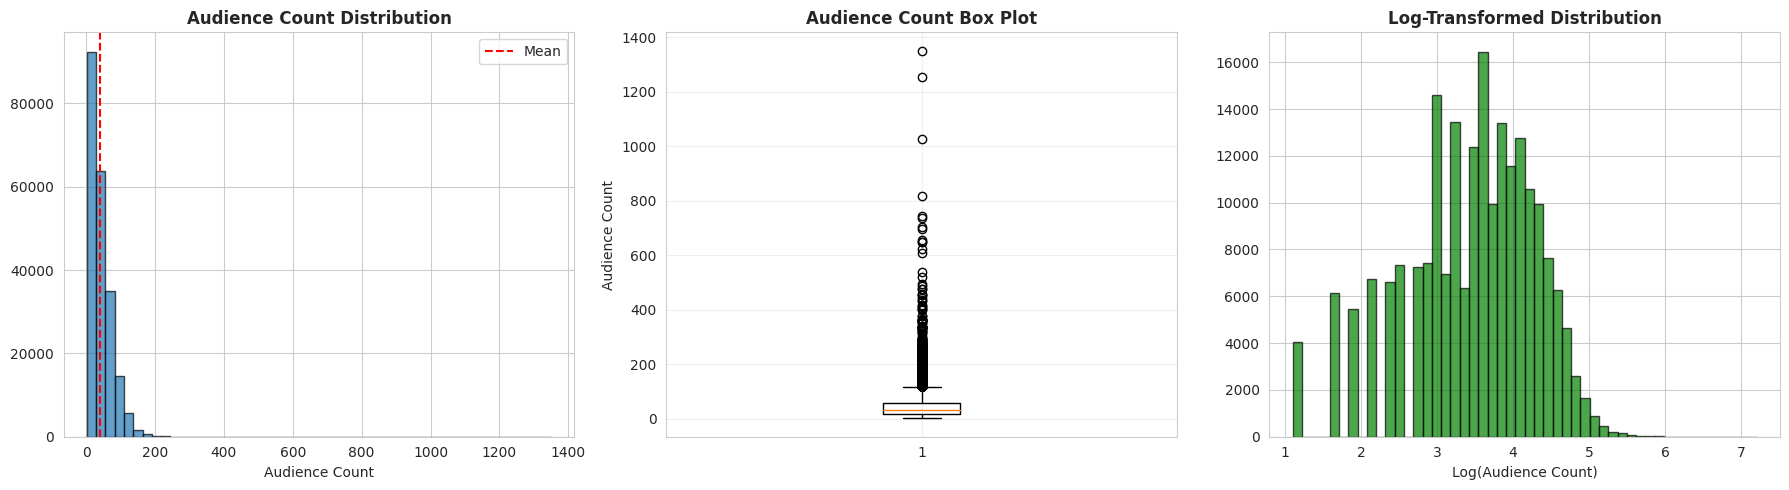


Skewness: 2.603
Kurtosis: 37.346

Temporal Patterns:


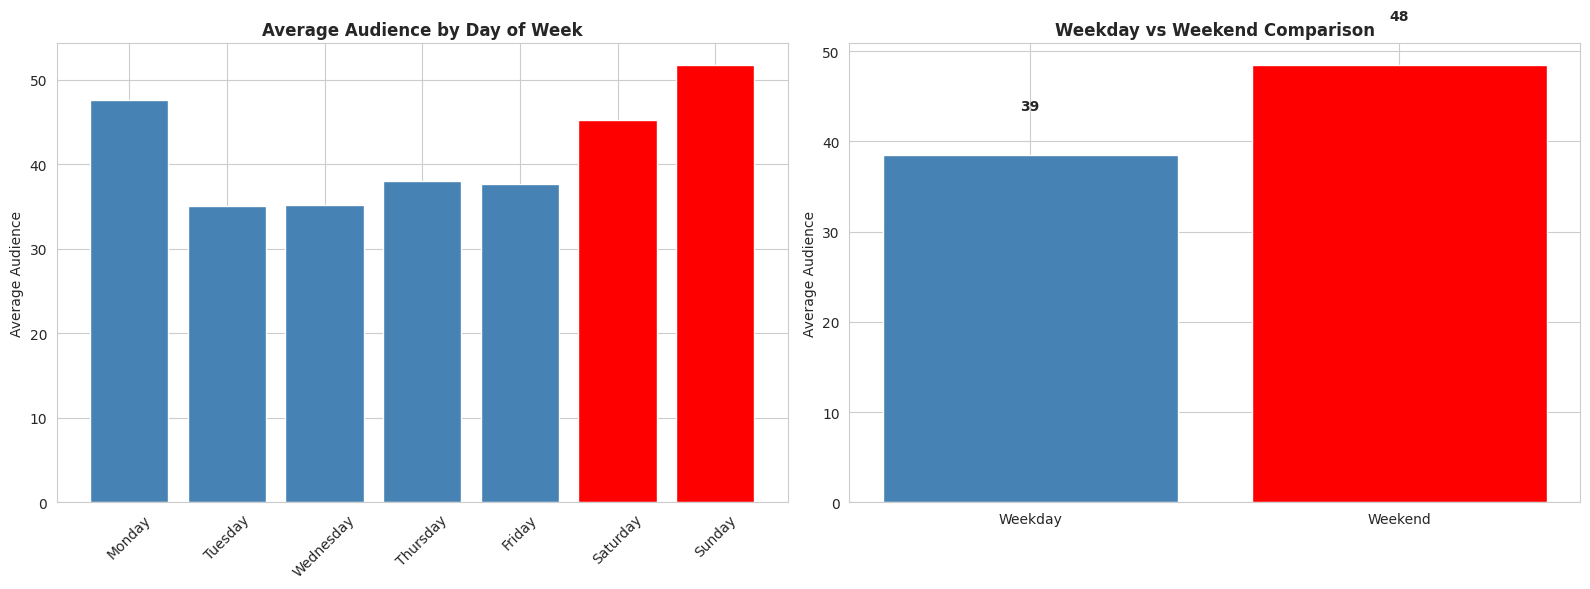

EDA completed


In [3]:
print("\nTarget Variable Statistics:")
print(booknow_visits['audience_count'].describe())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution
axes[0].hist(booknow_visits['audience_count'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('Audience Count Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Audience Count')
axes[0].axvline(booknow_visits['audience_count'].mean(), color='red', linestyle='--', label='Mean')
axes[0].legend()

# Box plot
axes[1].boxplot(booknow_visits['audience_count'])
axes[1].set_title('Audience Count Box Plot', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Audience Count')
axes[1].grid(True, alpha=0.3)

# Log-transformed
axes[2].hist(np.log1p(booknow_visits['audience_count']), bins=50, edgecolor='black', alpha=0.7, color='green')
axes[2].set_title('Log-Transformed Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Log(Audience Count)')

plt.tight_layout()
plt.show()

print(f"\nSkewness: {booknow_visits['audience_count'].skew():.3f}")
print(f"Kurtosis: {booknow_visits['audience_count'].kurtosis():.3f}")

# Temporal patterns
print("\nTemporal Patterns:")
booknow_visits['show_date'] = pd.to_datetime(booknow_visits['show_date'])
date_info['show_date'] = pd.to_datetime(date_info['show_date'])
df_temporal = booknow_visits.merge(date_info, on='show_date', how='left')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Day of week pattern
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_temporal['day_name'] = df_temporal['show_date'].dt.day_name()
daily_avg = df_temporal.groupby('day_name')['audience_count'].mean().reindex(day_order)
colors = ['red' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in daily_avg.index]
axes[0].bar(range(len(daily_avg)), daily_avg.values, color=colors)
axes[0].set_xticks(range(len(daily_avg)))
axes[0].set_xticklabels(daily_avg.index, rotation=45)
axes[0].set_title('Average Audience by Day of Week', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Audience')

# Weekend vs Weekday
df_temporal['is_weekend'] = df_temporal['show_date'].dt.dayofweek.isin([5, 6])
weekend_avg = df_temporal.groupby('is_weekend')['audience_count'].mean()
axes[1].bar(['Weekday', 'Weekend'], weekend_avg.values, color=['steelblue', 'red'])
axes[1].set_title('Weekday vs Weekend Comparison', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Audience')
for i, v in enumerate(weekend_avg.values):
    axes[1].text(i, v + 5, f'{v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("EDA completed")

In [4]:
def create_features(df_visits, date_info, booknow_booking, booknow_theaters, 
                   cinePOS_booking, cinePOS_theaters, movie_theater_relation, 
                   historical_stats=None):
    """Create features for modeling"""
    
    df_visits["show_date"] = pd.to_datetime(df_visits["show_date"], errors="coerce")
    date_info["show_date"] = pd.to_datetime(date_info["show_date"], errors="coerce")
    
    df = pd.merge(df_visits, date_info, on="show_date", how="left")
    
    # Temporal features
    df["year"] = df["show_date"].dt.year.astype("int32")
    df["month"] = df["show_date"].dt.month.astype("int32")
    df["day"] = df["show_date"].dt.day.astype("int32")
    df["week_of_year"] = df["show_date"].dt.isocalendar().week.astype("int32")
    df["is_weekend"] = df["show_date"].dt.dayofweek.isin([5, 6]).astype("int64")
    df["day_of_month"] = df["show_date"].dt.day
    df["quarter"] = df["show_date"].dt.quarter
    df["day_of_week_num"] = df["show_date"].dt.dayofweek
    
    # Day indicators
    df["is_friday"] = (df["day_of_week_num"] == 4).astype("int32")
    df["is_saturday"] = (df["day_of_week_num"] == 5).astype("int32")
    df["is_sunday"] = (df["day_of_week_num"] == 6).astype("int32")
    df["is_month_start"] = (df["day_of_month"] <= 7).astype("int32")
    df["is_month_end"] = (df["day_of_month"] >= 23).astype("int32")
    df["is_month_mid"] = ((df["day_of_month"] > 10) & (df["day_of_month"] <= 20)).astype("int32")
    
    df["days_since_start"] = (df["show_date"] - df["show_date"].min()).dt.days

    # Cyclical encoding
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    df["day_sin"] = np.sin(2 * np.pi * df["day_of_week_num"] / 7)
    df["day_cos"] = np.cos(2 * np.pi * df["day_of_week_num"] / 7)
    df["week_sin"] = np.sin(2 * np.pi * df["week_of_year"] / 52)
    df["week_cos"] = np.cos(2 * np.pi * df["week_of_year"] / 52)
    
    # Booking features
    booknow_booking['show_datetime'] = pd.to_datetime(booknow_booking['show_datetime'], errors='coerce')
    booknow_booking["booking_datetime"] = pd.to_datetime(booknow_booking["booking_datetime"])
    booknow_booking["lead_days"] = (booknow_booking["show_datetime"] - booknow_booking["booking_datetime"]).dt.days
    booknow_booking['show_date'] = booknow_booking['show_datetime'].dt.normalize()
    
    booking_agg = (
        booknow_booking.groupby(["book_theater_id", "show_date"], as_index=False)
        .agg(
            total_online_tickets=("tickets_booked", "sum"),
            avg_online_lead_days=("lead_days", "mean"),
            max_online_lead_days=("lead_days", "max"),
            min_online_lead_days=("lead_days", "min"),
            std_online_lead_days=("lead_days", "std"),
            median_online_lead_days=("lead_days", "median"),
            booking_count=("tickets_booked", "count"),
            avg_tickets_per_booking=("tickets_booked", "mean")
        )
    )
    
    df = df.merge(booking_agg, on=['book_theater_id','show_date'], how='left')
    
    booking_cols = ['total_online_tickets', 'avg_online_lead_days', 'max_online_lead_days',
                   'min_online_lead_days', 'std_online_lead_days', 'median_online_lead_days',
                   'booking_count', 'avg_tickets_per_booking']
    for col in booking_cols:
        df[col] = df[col].fillna(0)
    
    df = df.merge(booknow_theaters, on="book_theater_id", how="left")
    
    # POS data
    cinePOS_booking.drop_duplicates(inplace=True)
    pos_data = cinePOS_booking.merge(cinePOS_theaters, on="cine_theater_id", how="left")
    pos_data = movie_theater_relation.merge(pos_data, on="cine_theater_id", how="left")
    pos_data["show_date"] = pd.to_datetime(pos_data["show_datetime"]).dt.date
    
    pos_agg = (
        pos_data.groupby(["book_theater_id", "show_date"], as_index=False)
        .agg(
            total_pos_tickets=("tickets_sold", "sum"),
            pos_transaction_count=("tickets_sold", "count")
        )
    )
    
    df["show_date"] = pd.to_datetime(df["show_date"]).dt.date
    df = df.merge(pos_agg, on=["book_theater_id", "show_date"], how="left")
    df["total_pos_tickets"] = df["total_pos_tickets"].fillna(0)
    df["pos_transaction_count"] = df["pos_transaction_count"].fillna(0)
    
    # Interaction features
    df["total_tickets"] = df["total_online_tickets"] + df["total_pos_tickets"]
    df["online_ratio"] = np.where(
        df["total_tickets"] > 0,
        df["total_online_tickets"] / df["total_tickets"],
        0
    )
    df["has_online_booking"] = (df["total_online_tickets"] > 0).astype("int32")
    df["has_pos_booking"] = (df["total_pos_tickets"] > 0).astype("int32")
    
    df["is_last_minute"] = (df["avg_online_lead_days"] < 1).astype("int32")
    df["is_advance_booking"] = (df["avg_online_lead_days"] > 7).astype("int32")
    
    # Historical statistics
    if historical_stats is not None:
        df = df.merge(historical_stats['theater_stats'], on='book_theater_id', how='left')
        df = df.merge(historical_stats['area_stats'], on='theater_area', how='left')
        df = df.merge(historical_stats['type_stats'], on='theater_type', how='left')
        df = df.merge(historical_stats['dow_stats'], on='day_of_week', how='left')
        
        df["tickets_vs_avg"] = df["total_tickets"] - df["theater_avg_audience"].fillna(0)
        df["tickets_ratio"] = np.where(
            df["theater_avg_audience"].fillna(0) > 0,
            df["total_tickets"] / df["theater_avg_audience"],
            0
        )
    
    df.drop(['longitude', 'latitude'], axis=1, inplace=True, errors='ignore')
    df["ID"] = df["book_theater_id"].astype(str) + "_" + df["show_date"].astype(str)
    
    return df

def calculate_statistics(df):
    """Calculate historical statistics from training data"""
    
    theater_stats = df.groupby('book_theater_id')['audience_count'].agg([
        ('theater_avg_audience', 'mean'),
        ('theater_std_audience', 'std'),
        ('theater_max_audience', 'max'),
        ('theater_min_audience', 'min'),
        ('theater_median_audience', 'median'),
        ('theater_q75_audience', lambda x: x.quantile(0.75)),
        ('theater_q25_audience', lambda x: x.quantile(0.25))
    ]).reset_index()
    
    area_stats = df.groupby('theater_area')['audience_count'].agg([
        ('area_avg_audience', 'mean'),
        ('area_std_audience', 'std'),
        ('area_median_audience', 'median')
    ]).reset_index()
    
    type_stats = df.groupby('theater_type')['audience_count'].agg([
        ('type_avg_audience', 'mean'),
        ('type_std_audience', 'std'),
        ('type_median_audience', 'median')
    ]).reset_index()
    
    dow_stats = df.groupby('day_of_week')['audience_count'].agg([
        ('dow_avg_audience', 'mean'),
        ('dow_std_audience', 'std')
    ]).reset_index()
    
    return {
        'theater_stats': theater_stats,
        'area_stats': area_stats,
        'type_stats': type_stats,
        'dow_stats': dow_stats
    }

print("Creating features...")
df_full = create_features(
    df_visits=booknow_visits,
    date_info=date_info,
    booknow_booking=booknow_booking,
    booknow_theaters=booknow_theaters,
    cinePOS_booking=cinePOS_booking,
    cinePOS_theaters=cinePOS_theaters,
    movie_theater_relation=movie_theater_relation,
    historical_stats=None
)

print(f"Initial shape: {df_full.shape}")
df_full.drop_duplicates(inplace=True)
print(f"After removing duplicates: {df_full.shape}")

Creating features...
Initial shape: (214046, 44)
After removing duplicates: (214036, 44)


In [5]:
df_full["show_date"] = pd.to_datetime(df_full["show_date"])
df_full = df_full.sort_values('show_date')

split_date = df_full['show_date'].quantile(0.8)
train_data = df_full[df_full['show_date'] <= split_date].copy()
val_data = df_full[df_full['show_date'] > split_date].copy()

print(f"Training period: {train_data['show_date'].min()} to {train_data['show_date'].max()}")
print(f"Training samples: {len(train_data):,}")
print(f"Validation period: {val_data['show_date'].min()} to {val_data['show_date'].max()}")
print(f"Validation samples: {len(val_data):,}")

# Calculate statistics from training data only
print("\nCalculating historical statistics from training data...")
train_stats = calculate_statistics(train_data)

# Add statistics to both sets
train_data = train_data.merge(train_stats['theater_stats'], on='book_theater_id', how='left')
train_data = train_data.merge(train_stats['area_stats'], on='theater_area', how='left')
train_data = train_data.merge(train_stats['type_stats'], on='theater_type', how='left')
train_data = train_data.merge(train_stats['dow_stats'], on='day_of_week', how='left')

train_data["tickets_vs_avg"] = train_data["total_tickets"] - train_data["theater_avg_audience"].fillna(0)
train_data["tickets_ratio"] = np.where(
    train_data["theater_avg_audience"].fillna(0) > 0,
    train_data["total_tickets"] / train_data["theater_avg_audience"],
    0
)

val_data = val_data.merge(train_stats['theater_stats'], on='book_theater_id', how='left')
val_data = val_data.merge(train_stats['area_stats'], on='theater_area', how='left')
val_data = val_data.merge(train_stats['type_stats'], on='theater_type', how='left')
val_data = val_data.merge(train_stats['dow_stats'], on='day_of_week', how='left')

val_data["tickets_vs_avg"] = val_data["total_tickets"] - val_data["theater_avg_audience"].fillna(0)
val_data["tickets_ratio"] = np.where(
    val_data["theater_avg_audience"].fillna(0) > 0,
    val_data["total_tickets"] / val_data["theater_avg_audience"],
    0
)

print(f"Final training shape: {train_data.shape}")
print(f"Final validation shape: {val_data.shape}")

Training period: 2023-01-01 00:00:00 to 2023-12-26 00:00:00
Training samples: 171,512
Validation period: 2023-12-27 00:00:00 to 2024-02-28 00:00:00
Validation samples: 42,524

Calculating historical statistics from training data...
Final training shape: (171512, 61)
Final validation shape: (42524, 61)


In [6]:
feature_list = [
    # Temporal
    'day_of_week', 'year', 'month', 'day', 'week_of_year', 'is_weekend', 
    'day_of_month', 'quarter', 'day_of_week_num',
    'is_friday', 'is_saturday', 'is_sunday',
    'is_month_start', 'is_month_end', 'is_month_mid',
    'days_since_start',
    'month_sin', 'month_cos', 'day_sin', 'day_cos', 'week_sin', 'week_cos',
    
    # Booking
    'total_online_tickets', 'avg_online_lead_days', 'max_online_lead_days',
    'min_online_lead_days', 'std_online_lead_days', 'median_online_lead_days',
    'booking_count', 'avg_tickets_per_booking',
    
    # Theater
    'theater_type', 'theater_area',
    
    # POS
    'total_pos_tickets', 'pos_transaction_count',
    
    # Interactions
    'total_tickets', 'online_ratio', 'has_online_booking', 'has_pos_booking',
    'is_last_minute', 'is_advance_booking',
    
    # Historical
    'theater_avg_audience', 'theater_std_audience', 'theater_max_audience',
    'theater_min_audience', 'theater_median_audience',
    'theater_q75_audience', 'theater_q25_audience',
    'area_avg_audience', 'area_std_audience', 'area_median_audience',
    'type_avg_audience', 'type_std_audience', 'type_median_audience',
    'dow_avg_audience', 'dow_std_audience',
    
    # Stat interactions
    'tickets_vs_avg', 'tickets_ratio'
]

X_train = train_data[feature_list].copy()
y_train = train_data['audience_count'].copy()
X_val = val_data[feature_list].copy()
y_val = val_data['audience_count'].copy()

categorical_features = ['theater_type', 'theater_area', 'day_of_week']
numerical_features = [f for f in feature_list if f not in categorical_features]

print(f"Total features: {len(feature_list)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Numerical features: {len(numerical_features)}")

# Imputation
cat_imputer = SimpleImputer(strategy='most_frequent')
num_imputer = SimpleImputer(strategy='mean')

X_train[categorical_features] = cat_imputer.fit_transform(X_train[categorical_features])
X_val[categorical_features] = cat_imputer.transform(X_val[categorical_features])

X_train[numerical_features] = num_imputer.fit_transform(X_train[numerical_features])
X_val[numerical_features] = num_imputer.transform(X_val[numerical_features])

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
train_cat_encoded = encoder.fit_transform(X_train[categorical_features])
val_cat_encoded = encoder.transform(X_val[categorical_features])
cat_cols = encoder.get_feature_names_out(categorical_features)

# Scaling
scaler = StandardScaler()
binary_features = ['is_weekend', 'is_friday', 'is_saturday', 'is_sunday', 'is_month_start',
                  'is_month_end', 'is_month_mid', 'has_online_booking', 'has_pos_booking',
                  'is_last_minute', 'is_advance_booking']
scale_features = [f for f in numerical_features if f not in binary_features and 
                 f not in ['year', 'month', 'day', 'quarter', 'day_of_week_num']]

X_train[scale_features] = scaler.fit_transform(X_train[scale_features])
X_val[scale_features] = scaler.transform(X_val[scale_features])

# Combine features
other_features = [f for f in X_train.columns if f not in categorical_features]

X_train_final = pd.DataFrame(
    np.hstack([train_cat_encoded, X_train[other_features].values]),
    columns=list(cat_cols) + other_features
)

X_val_final = pd.DataFrame(
    np.hstack([val_cat_encoded, X_val[other_features].values]),
    columns=list(cat_cols) + other_features
)

print(f"Final feature count: {X_train_final.shape[1]}")

Total features: 57
Categorical features: 3
Numerical features: 54
Final feature count: 136


In [7]:
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_regression

# PCA Analysis
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_final)
X_val_pca = pca.transform(X_val_final)
print(f"PCA: Reduced from {X_train_final.shape[1]} to {X_train_pca.shape[1]} components (95% variance)")

# Feature Selection
k_best = 50
selector = SelectKBest(score_func=f_regression, k=k_best)
X_train_kbest = selector.fit_transform(X_train_final, y_train)
X_val_kbest = selector.transform(X_val_final)
selected_features = X_train_final.columns[selector.get_support()].tolist()
print(f"Feature Selection: Selected top {k_best} features using f_regression")

# Test with a simple model to compare
from sklearn.linear_model import Ridge
test_model = Ridge(alpha=1.0, random_state=42)

test_model.fit(X_train_final, y_train)
r2_original = r2_score(y_val, test_model.predict(X_val_final))

test_model.fit(X_train_pca, y_train)
r2_pca = r2_score(y_val, test_model.predict(X_val_pca))

test_model.fit(X_train_kbest, y_train)
r2_kbest = r2_score(y_val, test_model.predict(X_val_kbest))

print(f"\nComparison on Ridge model:")
print(f"  Original features: R² = {r2_original:.4f}")
print(f"  PCA features: R² = {r2_pca:.4f}")
print(f"  Selected features: R² = {r2_kbest:.4f}")
print(f"Decision: Using original features for better interpretability and performance")

PCA: Reduced from 136 to 14 components (95% variance)
Feature Selection: Selected top 50 features using f_regression

Comparison on Ridge model:
  Original features: R² = -135.2264
  PCA features: R² = 0.4256
  Selected features: R² = 0.3379
Decision: Using original features for better interpretability and performance


In [8]:
models = {
    # MILESTONE 2: Linear Models & SGD
    'Ridge': Ridge(alpha=5.0, random_state=42),
    'ElasticNet': ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=42, max_iter=2000),
    'SGD': SGDRegressor(max_iter=1000, tol=1e-3, random_state=42, early_stopping=True, validation_fraction=0.1),
    
    # MILESTONE 3: Naive Bayes, KNN, SVM
    'KNN': KNeighborsRegressor(n_neighbors=10, weights='distance', n_jobs=-1),
    'SVR': SVR(kernel='rbf', C=1.0, epsilon=0.1),
    
    # MILESTONE 4: Ensemble Methods
    'Random Forest': RandomForestRegressor(
        n_estimators=300, max_depth=15, min_samples_split=4,
        min_samples_leaf=2, max_features='sqrt',
        random_state=42, n_jobs=-1
    ),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=300, max_depth=15, min_samples_split=4,
        min_samples_leaf=2, max_features='sqrt',
        random_state=42, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200, max_depth=7, learning_rate=0.05,
        subsample=0.8, random_state=42
    ),
    'XGBoost': XGBRegressor(
        n_estimators=300, max_depth=8, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=300, max_depth=8, learning_rate=0.05,
        num_leaves=50, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbose=-1
    ),
    
    # MILESTONE 4: Multi-layer Perceptron
    'MLP': MLPRegressor(
        hidden_layer_sizes=(100, 50), activation='relu',
        solver='adam', max_iter=500, random_state=42,
        early_stopping=True, validation_fraction=0.1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    start_time = time.time()
    
    # For SVR, use subset of data (too slow otherwise)
    if name == 'SVR':
        sample_size = min(10000, len(X_train_final))
        sample_idx = np.random.choice(len(X_train_final), sample_size, replace=False)
        model.fit(X_train_final.iloc[sample_idx], y_train.iloc[sample_idx])
    else:
        model.fit(X_train_final, y_train)
    
    train_pred = model.predict(X_train_final)
    val_pred = model.predict(X_val_final)
    
    train_r2 = r2_score(y_train, train_pred)
    val_r2 = r2_score(y_val, val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    train_time = time.time() - start_time
    
    results.append({
        'Model': name,
        'Train R²': train_r2,
        'Val R²': val_r2,
        'Val RMSE': val_rmse,
        'Time (s)': train_time,
        'Overfit Gap': train_r2 - val_r2
    })
    
    trained_models[name] = model
    
    print(f"  Train R² = {train_r2:.4f}")
    print(f"  Val R² = {val_r2:.4f}")
    print(f"  Val RMSE = {val_rmse:.2f}")

results_df = pd.DataFrame(results).sort_values('Val R²', ascending=False)

print("MODEL COMPARISON:")
print(results_df.to_string(index=False))


Training Ridge...
  Train R² = 0.4754
  Val R² = -23.6631
  Val RMSE = 158.28

Training ElasticNet...
  Train R² = 0.4594
  Val R² = 0.4317
  Val RMSE = 24.03

Training SGD...
  Train R² = -54843540562757181769777152.0000
  Val R² = -51660333408243548789145600.0000
  Val RMSE = 229070383461328.72

Training KNN...
  Train R² = 0.9992
  Val R² = 0.3913
  Val RMSE = 24.87

Training SVR...
  Train R² = -0.0540
  Val R² = -0.0429
  Val RMSE = 32.55

Training Random Forest...
  Train R² = 0.6296
  Val R² = 0.5137
  Val RMSE = 22.22

Training Extra Trees...
  Train R² = 0.5495
  Val R² = 0.5035
  Val RMSE = 22.46

Training Gradient Boosting...
  Train R² = 0.6184
  Val R² = 0.4519
  Val RMSE = 23.60

Training XGBoost...
  Train R² = 0.6737
  Val R² = 0.4485
  Val RMSE = 23.67

Training LightGBM...
  Train R² = 0.5825
  Val R² = 0.4856
  Val RMSE = 22.86

Training MLP...
  Train R² = 0.4991
  Val R² = 0.1949
  Val RMSE = 28.60
MODEL COMPARISON:
            Model      Train R²        Val R²   

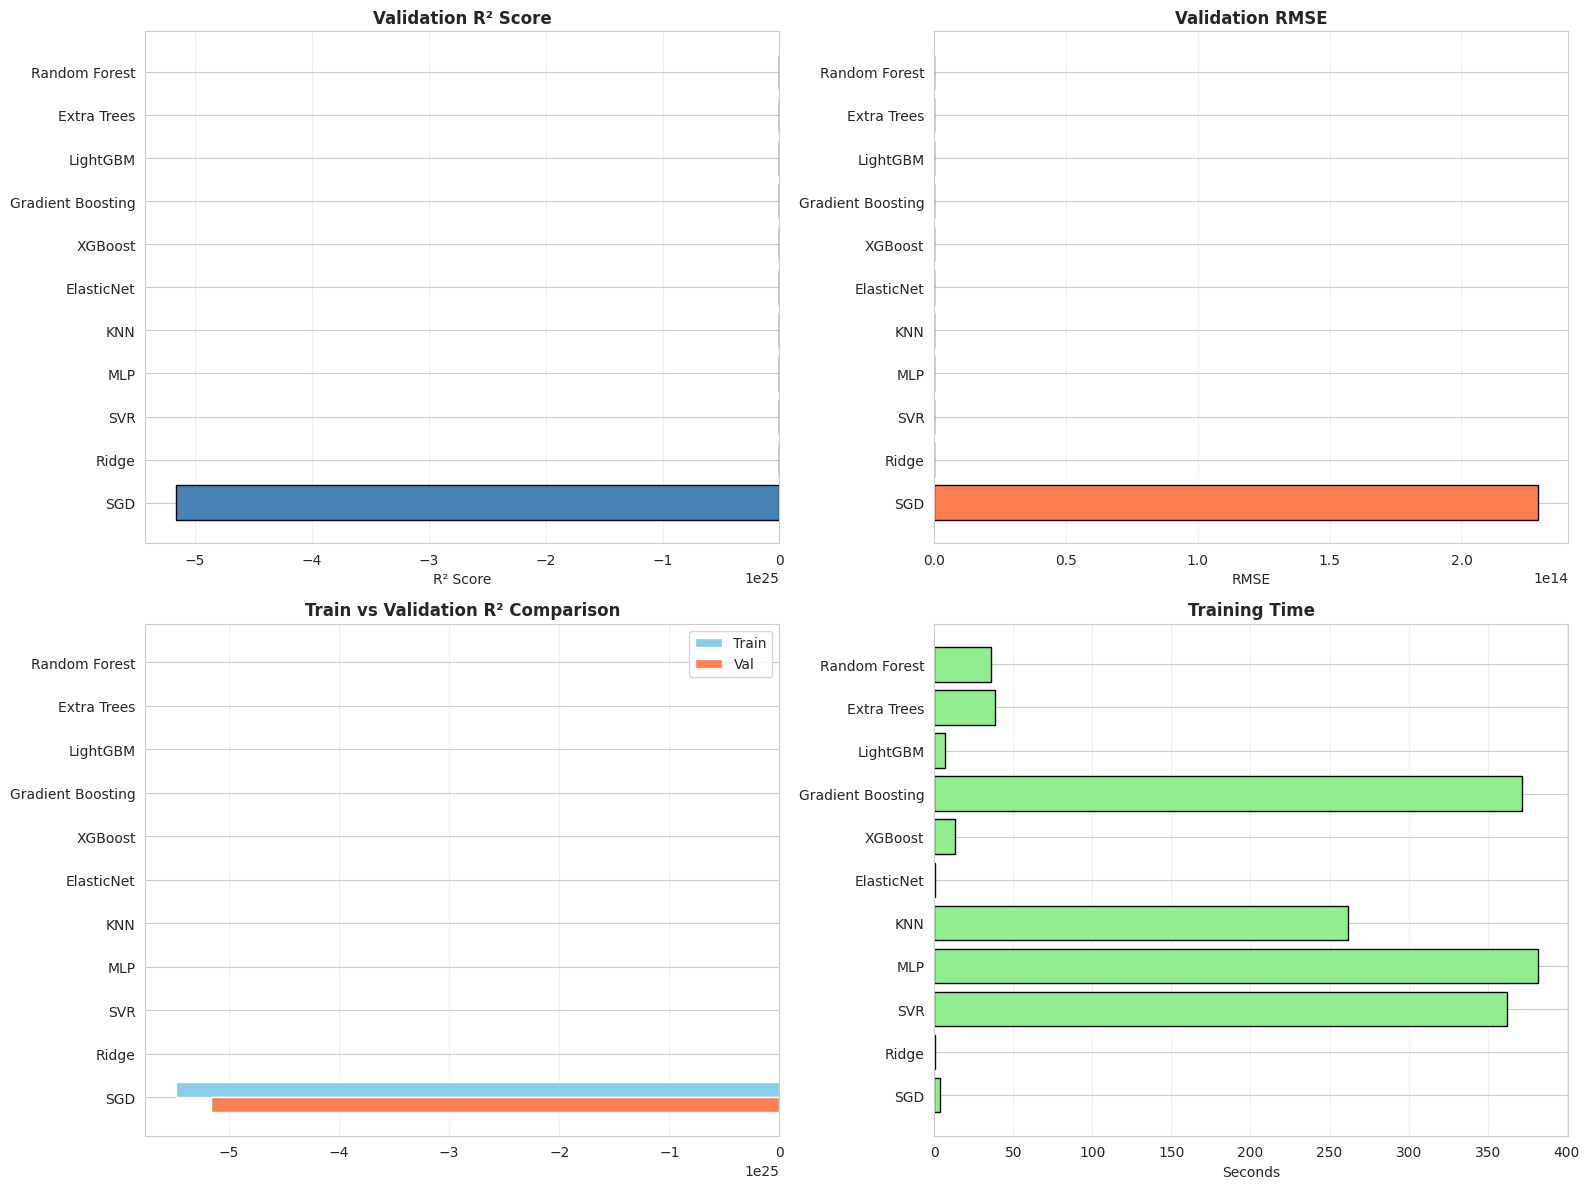


Best Model: Random Forest
Validation R² = 0.5137
Validation RMSE = 22.22


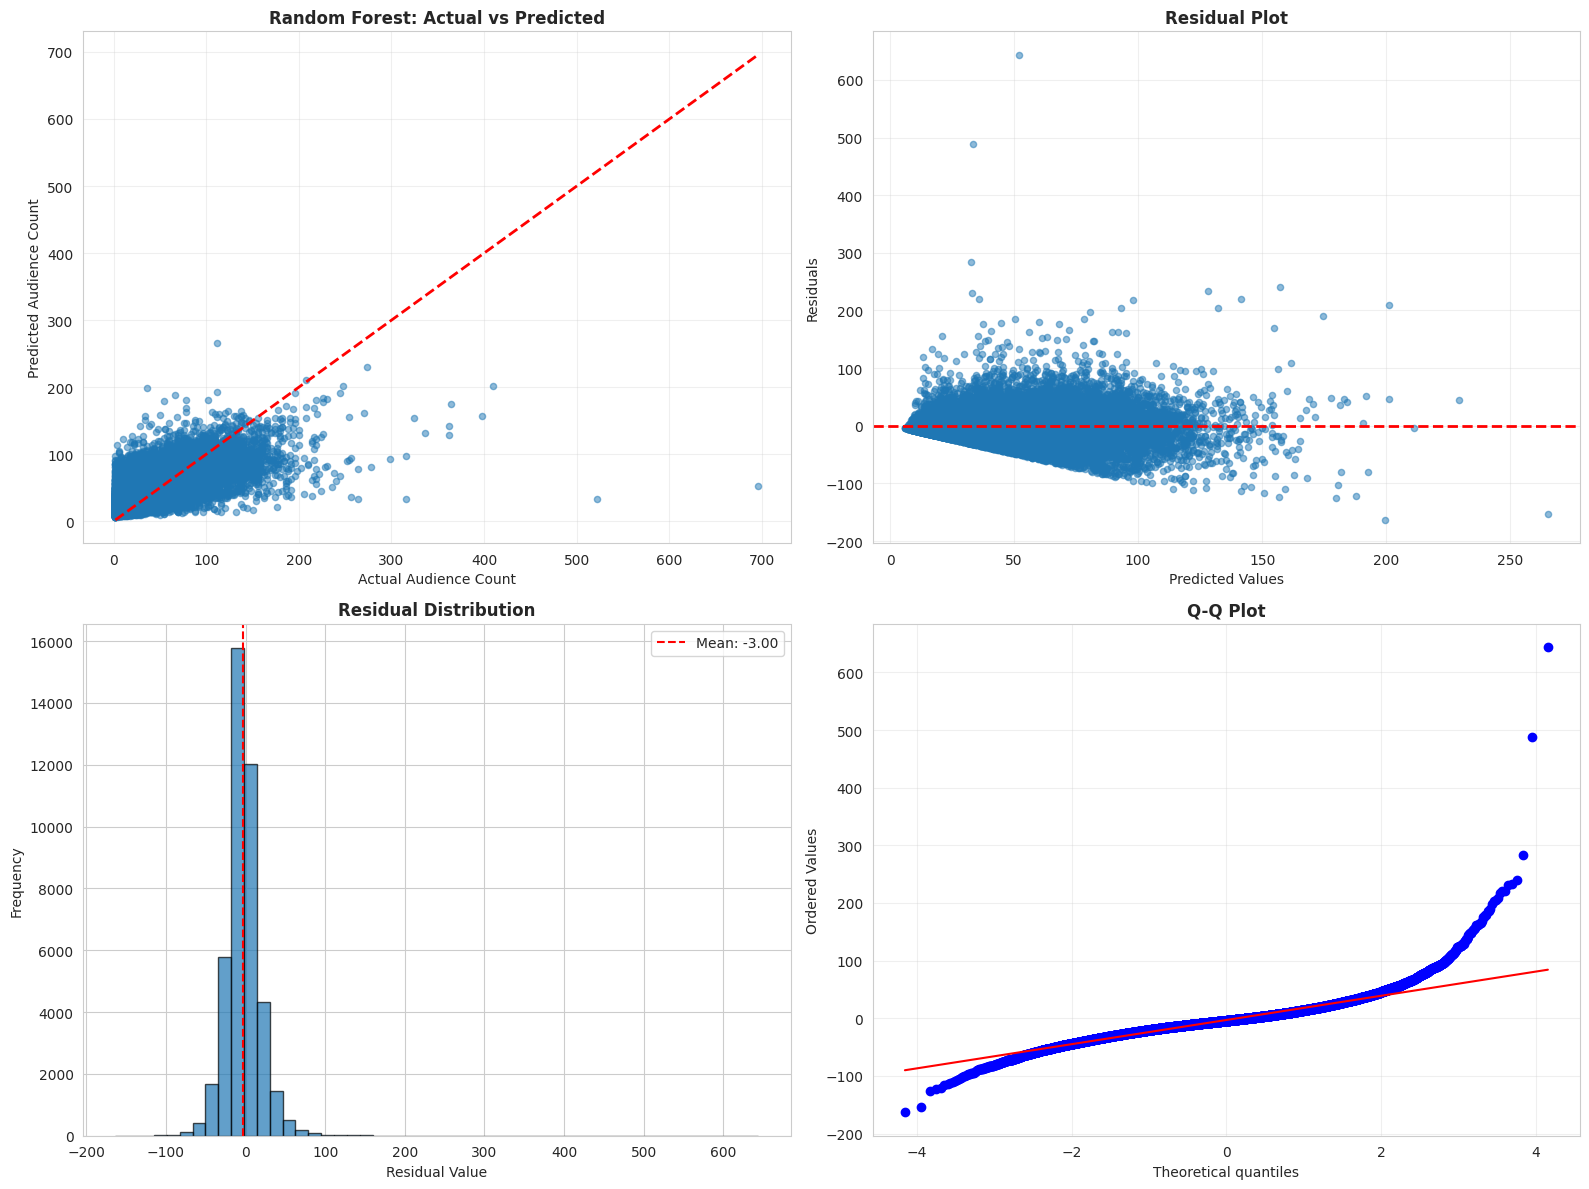


Feature Importance Analysis - Random Forest


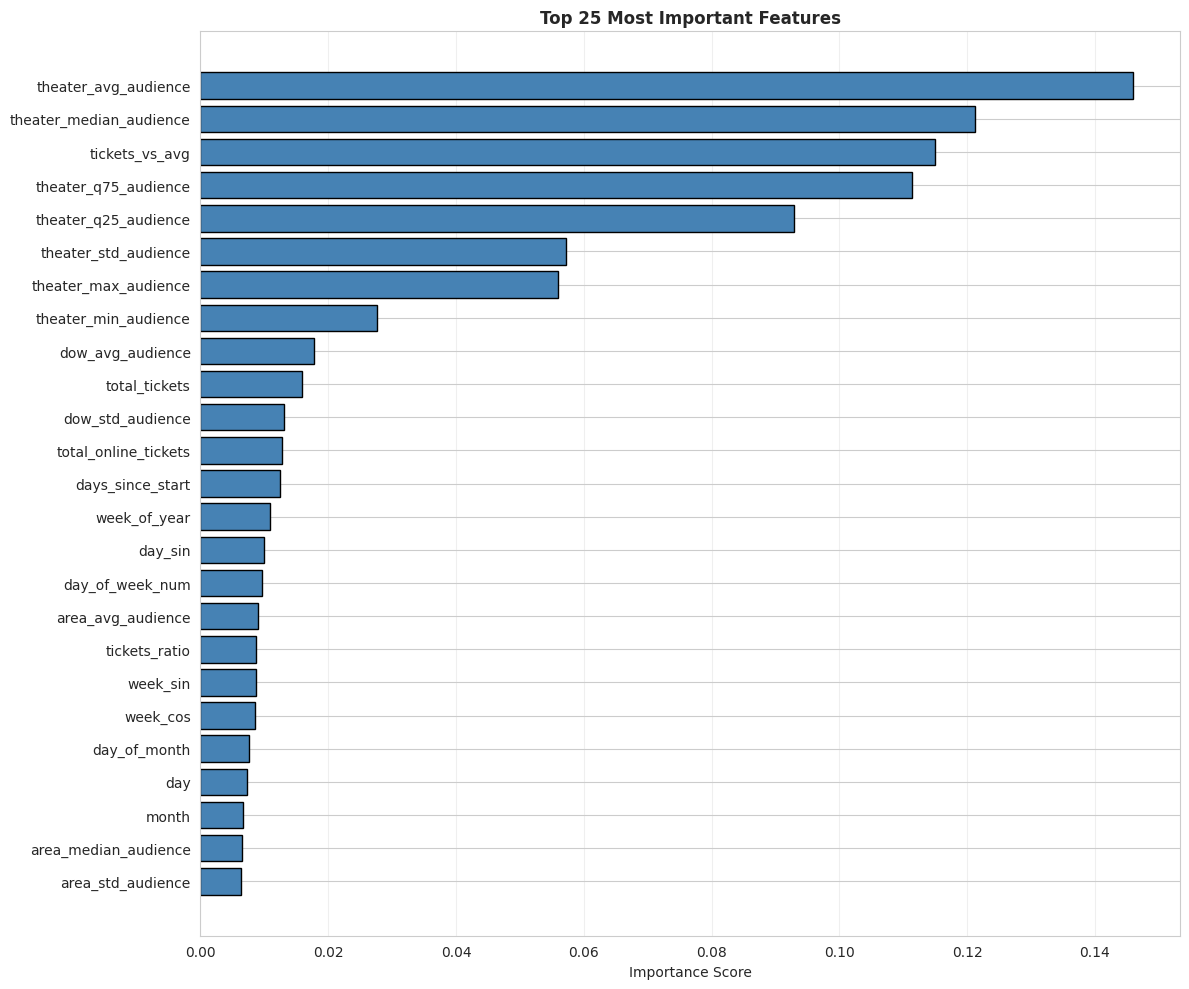


Top 10 Most Important Features:
                Feature  Importance
   theater_avg_audience    0.146028
theater_median_audience    0.121245
         tickets_vs_avg    0.114971
   theater_q75_audience    0.111351
   theater_q25_audience    0.092985
   theater_std_audience    0.057202
   theater_max_audience    0.055978
   theater_min_audience    0.027653
       dow_avg_audience    0.017734
          total_tickets    0.015942


Overfitting Analysis:
Random Forest   Gap = 0.1158 - Slight overfitting
Extra Trees     Gap = 0.0460 - Good generalization
LightGBM        Gap = 0.0969 - Good generalization
Gradient Boosting Gap = 0.1665 - Slight overfitting
XGBoost         Gap = 0.2252 - High overfitting
ElasticNet      Gap = 0.0277 - Good generalization
KNN             Gap = 0.6080 - High overfitting
MLP             Gap = 0.3043 - High overfitting
SVR             Gap = -0.0111 - Good generalization
Ridge           Gap = 24.1385 - High overfitting
SGD             Gap = -318320715451363298063155

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Validation R² comparison
axes[0, 0].barh(results_df['Model'], results_df['Val R²'], color='steelblue', edgecolor='black')
axes[0, 0].set_title('Validation R² Score', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('R² Score')
axes[0, 0].invert_yaxis()
axes[0, 0].grid(True, alpha=0.3, axis='x')

# Validation RMSE comparison
axes[0, 1].barh(results_df['Model'], results_df['Val RMSE'], color='coral', edgecolor='black')
axes[0, 1].set_title('Validation RMSE', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('RMSE')
axes[0, 1].invert_yaxis()
axes[0, 1].grid(True, alpha=0.3, axis='x')

# Train vs Val R²
x_pos = np.arange(len(results_df))
width = 0.35
axes[1, 0].barh(x_pos - width/2, results_df['Train R²'], width, label='Train', color='skyblue')
axes[1, 0].barh(x_pos + width/2, results_df['Val R²'], width, label='Val', color='coral')
axes[1, 0].set_title('Train vs Validation R² Comparison', fontsize=12, fontweight='bold')
axes[1, 0].set_yticks(x_pos)
axes[1, 0].set_yticklabels(results_df['Model'])
axes[1, 0].legend()
axes[1, 0].invert_yaxis()
axes[1, 0].grid(True, alpha=0.3, axis='x')

# Training time
axes[1, 1].barh(results_df['Model'], results_df['Time (s)'], color='lightgreen', edgecolor='black')
axes[1, 1].set_title('Training Time', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Seconds')
axes[1, 1].invert_yaxis()
axes[1, 1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
best_val_pred = best_model.predict(X_val_final)

print(f"\nBest Model: {best_model_name}")
print(f"Validation R² = {results_df.iloc[0]['Val R²']:.4f}")
print(f"Validation RMSE = {results_df.iloc[0]['Val RMSE']:.2f}")

# Prediction analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Actual vs Predicted
axes[0, 0].scatter(y_val, best_val_pred, alpha=0.5, s=20)
axes[0, 0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
axes[0, 0].set_title(f'{best_model_name}: Actual vs Predicted', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Actual Audience Count')
axes[0, 0].set_ylabel('Predicted Audience Count')
axes[0, 0].grid(True, alpha=0.3)

# Residual plot
residuals = y_val - best_val_pred
axes[0, 1].scatter(best_val_pred, residuals, alpha=0.5, s=20)
axes[0, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[0, 1].set_title('Residual Plot', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Predicted Values')
axes[0, 1].set_ylabel('Residuals')
axes[0, 1].grid(True, alpha=0.3)

# Residual distribution
axes[1, 0].hist(residuals, bins=50, edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Residual Distribution', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Residual Value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].axvline(residuals.mean(), color='red', linestyle='--', label=f'Mean: {residuals.mean():.2f}')
axes[1, 0].legend()

# Q-Q plot
stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Feature importance
if best_model_name in ['Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'LightGBM']:
    print(f"\nFeature Importance Analysis - {best_model_name}")
    
    feature_importance = best_model.feature_importances_
    importance_df = pd.DataFrame({
        'Feature': X_train_final.columns,
        'Importance': feature_importance
    }).sort_values('Importance', ascending=False)
    
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    
    top_features = 25
    top_imp = importance_df.head(top_features)
    ax.barh(range(len(top_imp)), top_imp['Importance'], color='steelblue', edgecolor='black')
    ax.set_yticks(range(len(top_imp)))
    ax.set_yticklabels(top_imp['Feature'])
    ax.set_title(f'Top {top_features} Most Important Features', fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.show()
    
    print("\nTop 10 Most Important Features:")
    print(importance_df.head(10).to_string(index=False))

# Overfitting analysis
print("\n\nOverfitting Analysis:")
for _, row in results_df.iterrows():
    gap = row['Overfit Gap']
    if gap < 0.10:
        status = "Good generalization"
    elif gap < 0.20:
        status = "Slight overfitting"
    else:
        status = "High overfitting"
    print(f"{row['Model']:15s} Gap = {gap:.4f} - {status}")

In [10]:
sample_submission['book_theater_id'], sample_submission['show_date'] = zip(
    *sample_submission['ID'].apply(lambda x: (f"{x.split('_')[0]}_{x.split('_')[1]}", x.split('_')[2]))
)

test_data = sample_submission[['book_theater_id', 'show_date']].copy()

print("Creating features for test data...")
test_features = create_features(
    df_visits=test_data,
    date_info=date_info,
    booknow_booking=booknow_booking,
    booknow_theaters=booknow_theaters,
    cinePOS_booking=cinePOS_booking,
    cinePOS_theaters=cinePOS_theaters,
    movie_theater_relation=movie_theater_relation,
    historical_stats=train_stats
)

X_test = test_features[feature_list].copy()

# Preprocess test data
X_test[categorical_features] = cat_imputer.transform(X_test[categorical_features])
X_test[numerical_features] = num_imputer.transform(X_test[numerical_features])

test_cat_encoded = encoder.transform(X_test[categorical_features])
X_test[scale_features] = scaler.transform(X_test[scale_features])

X_test_final = pd.DataFrame(
    np.hstack([test_cat_encoded, X_test[other_features].values]),
    columns=list(cat_cols) + other_features
)

print(f"Test data shape: {X_test_final.shape}")

Creating features for test data...
Test data shape: (38062, 136)


In [11]:
# Select models with good performance and low overfitting
selected_models = results_df[
    (results_df['Val R²'] > 0.45) & 
    (results_df['Overfit Gap'] < 0.15)
].copy()

if len(selected_models) == 0:
    selected_models = results_df.head(3).copy()

print(f"Selected {len(selected_models)} models for ensemble:")
print(selected_models[['Model', 'Val R²', 'Val RMSE', 'Overfit Gap']].to_string(index=False))

# Calculate weights based on inverse RMSE squared
selected_models['weight_score'] = 1 / (selected_models['Val RMSE'] ** 2)
selected_models['weight'] = selected_models['weight_score'] / selected_models['weight_score'].sum()

print("\nEnsemble Weights:")
for _, row in selected_models.iterrows():
    print(f"  {row['Model']:15s}: {row['weight']:.4f}")

# Generate ensemble predictions
ensemble_predictions = np.zeros(len(X_test_final))

for _, row in selected_models.iterrows():
    model_name = row['Model']
    weight = row['weight']
    model = trained_models[model_name]
    predictions = model.predict(X_test_final)
    ensemble_predictions += weight * predictions

print(f"\nEnsemble prediction statistics:")
print(f"  Mean: {ensemble_predictions.mean():.2f}")
print(f"  Median: {np.median(ensemble_predictions):.2f}")
print(f"  Std: {ensemble_predictions.std():.2f}")
print(f"  Min: {ensemble_predictions.min():.2f}")
print(f"  Max: {ensemble_predictions.max():.2f}")

Selected 3 models for ensemble:
        Model   Val R²  Val RMSE  Overfit Gap
Random Forest 0.513705 22.224916     0.115846
  Extra Trees 0.503452 22.457985     0.046042
     LightGBM 0.485621 22.857674     0.096891

Ensemble Weights:
  Random Forest  : 0.3419
  Extra Trees    : 0.3348
  LightGBM       : 0.3232

Ensemble prediction statistics:
  Mean: 42.99
  Median: 38.66
  Std: 22.36
  Min: 7.44
  Max: 198.04


Submission file created: submission.csv
Total predictions: 38,062


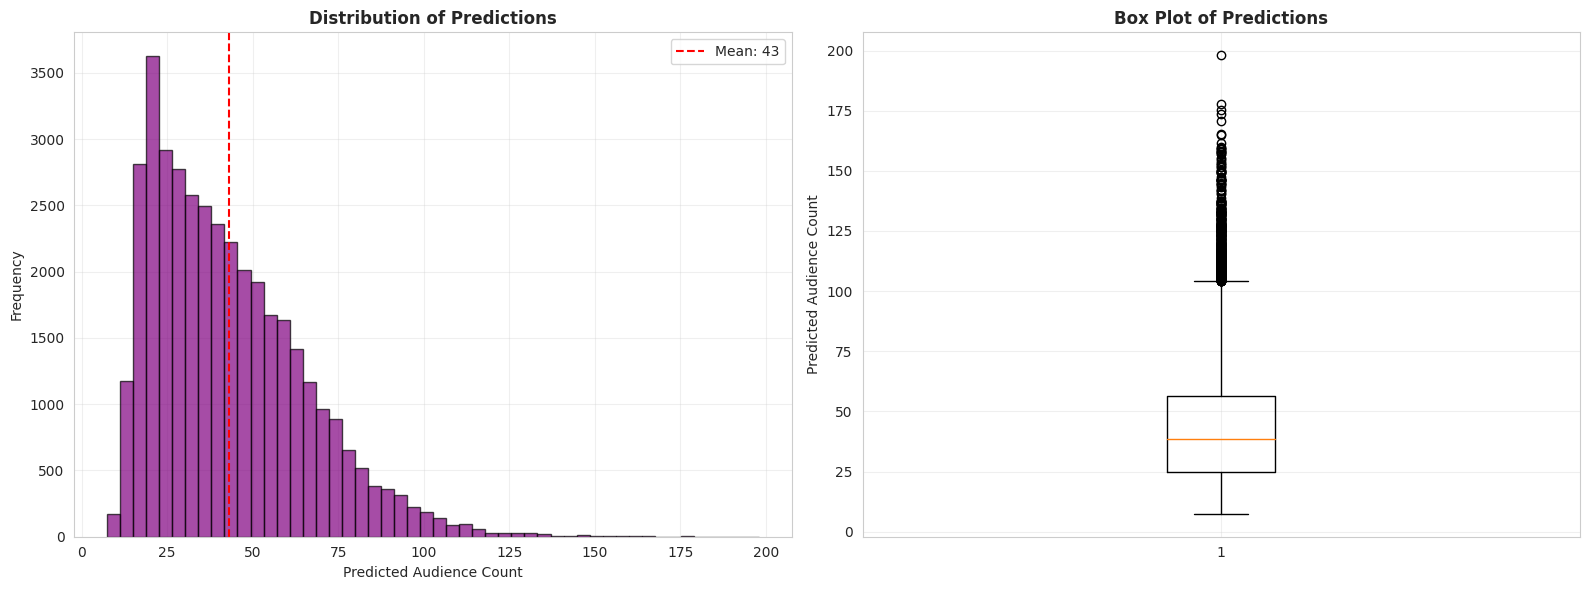

In [12]:
submission = pd.DataFrame({
    'ID': sample_submission['ID'],
    'audience_count': np.clip(ensemble_predictions, 0, None)
})

submission.to_csv('submission.csv', index=False)

print("Submission file created: submission.csv")
print(f"Total predictions: {len(submission):,}")

# Visualize predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(ensemble_predictions, bins=50, edgecolor='black', alpha=0.7, color='purple')
axes[0].set_title('Distribution of Predictions', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Audience Count')
axes[0].set_ylabel('Frequency')
axes[0].axvline(ensemble_predictions.mean(), color='red', linestyle='--', 
                label=f'Mean: {ensemble_predictions.mean():.0f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].boxplot(ensemble_predictions)
axes[1].set_title('Box Plot of Predictions', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Predicted Audience Count')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()